# 01 · Exploração dos dados (NASA C-MAPSS, FD001)

**Objetivo:** entender os dados antes de modelar. Ao final, queremos responder:
1. Quantos motores e quantos ciclos temos?
2. Quais sensores **não servem** (constantes)?
3. Quais sensores **mostram o desgaste** conforme o motor se aproxima da falha?

> Cada motor roda até falhar. **RUL** (*Remaining Useful Life*) = quantos ciclos ainda faltam para a falha.
> Rode as células em ordem (`Shift+Enter`) e leia os comentários.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Garante que o pacote do projeto seja encontrado (mesmo sem `pip install -e .`)
SRC = Path("..") / "src"
if SRC.exists():
    sys.path.insert(0, str(SRC.resolve()))

from cmapss.data import SENSORS, load_train

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

train = load_train(DATA_DIR)
train.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


## 1. Visão geral
Cada linha é **um ciclo de um motor**: `unit` (id do motor), `cycle`, 3 condições operacionais (`op1..3`),
21 sensores (`s1..s21`) e a coluna `RUL` que criamos (limitada a 125, valor comum na literatura:
acima disso o motor é considerado "saudável").

In [2]:
print("Linhas:", len(train), "| Colunas:", train.shape[1])
print("Motores:", train["unit"].nunique())

vida = train.groupby("unit")["cycle"].max()
print("\nVida (ciclos até a falha) por motor:")
print(vida.describe().round(1))

Linhas: 20631 | Colunas: 27
Motores: 100

Vida (ciclos até a falha) por motor:
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


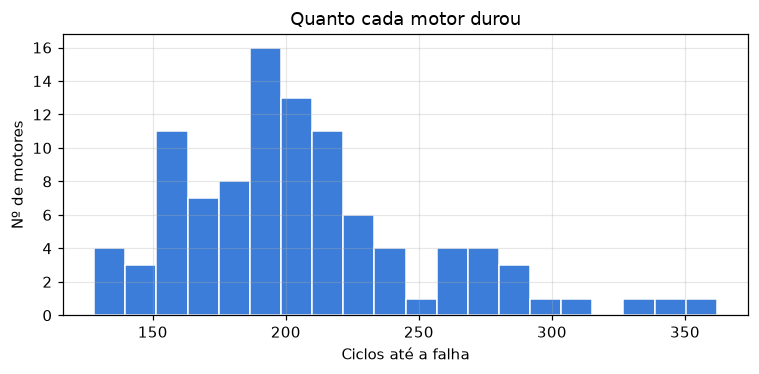

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(vida, bins=20, color="#3b7dd8", edgecolor="white")
ax.set_xlabel("Ciclos até a falha")
ax.set_ylabel("Nº de motores")
ax.set_title("Quanto cada motor durou")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribuicao_vida.png")
plt.show()

**Pergunta para você:** os motores duram todos o mesmo tempo? Qual a diferença entre o que durou menos e o que durou mais?
Isso importa: se todos falhassem no mesmo ciclo, bastaria olhar o número do ciclo, sem precisar de ML.

R: vemos claramente que a depender do motor ele pode falhar antes ou depois mas temos uma tendencia e é essa tendencia que estamos estudando

## 2. Sensores inúteis (constantes)
Um sensor que nunca muda não carrega informação. Vamos medir a variação de cada um.

In [4]:
resumo = train[SENSORS].agg(["mean", "std", "nunique"]).T.round(4)
resumo["constante?"] = resumo["nunique"] <= 1
resumo

,mean,std,nunique,constante?
s1,518.6700,0.0000,1.0,True
s2,642.6809,0.5001,310.0,False
s3,1590.5231,6.1311,3012.0,False
s4,1408.9338,9.0006,4051.0,False
s5,14.6200,0.0000,1.0,True
s6,21.6098,0.0014,2.0,False
s7,553.3677,0.8851,513.0,False
s8,2388.0967,0.0710,53.0,False
s9,9065.2429,22.0829,6403.0,False
s10,1.3000,0.0000,1.0,True


In [5]:
constantes = resumo.index[resumo["nunique"] <= 1].tolist()
uteis = [s for s in SENSORS if s not in constantes]
print("Constantes (descartar):", constantes)
print("Candidatos úteis:", len(uteis), uteis)

Constantes (descartar): ['s1', 's5', 's10', 's16', 's18', 's19']
Candidatos úteis: 15 ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. A vida de um motor, sensor por sensor
Para cada motor, olhamos o sensor **contra o tempo que falta para a falha**
(eixo x invertido: à direita, a falha). Sensores que "sobem" ou "descem" de forma clara perto do fim
mostram o desgaste.

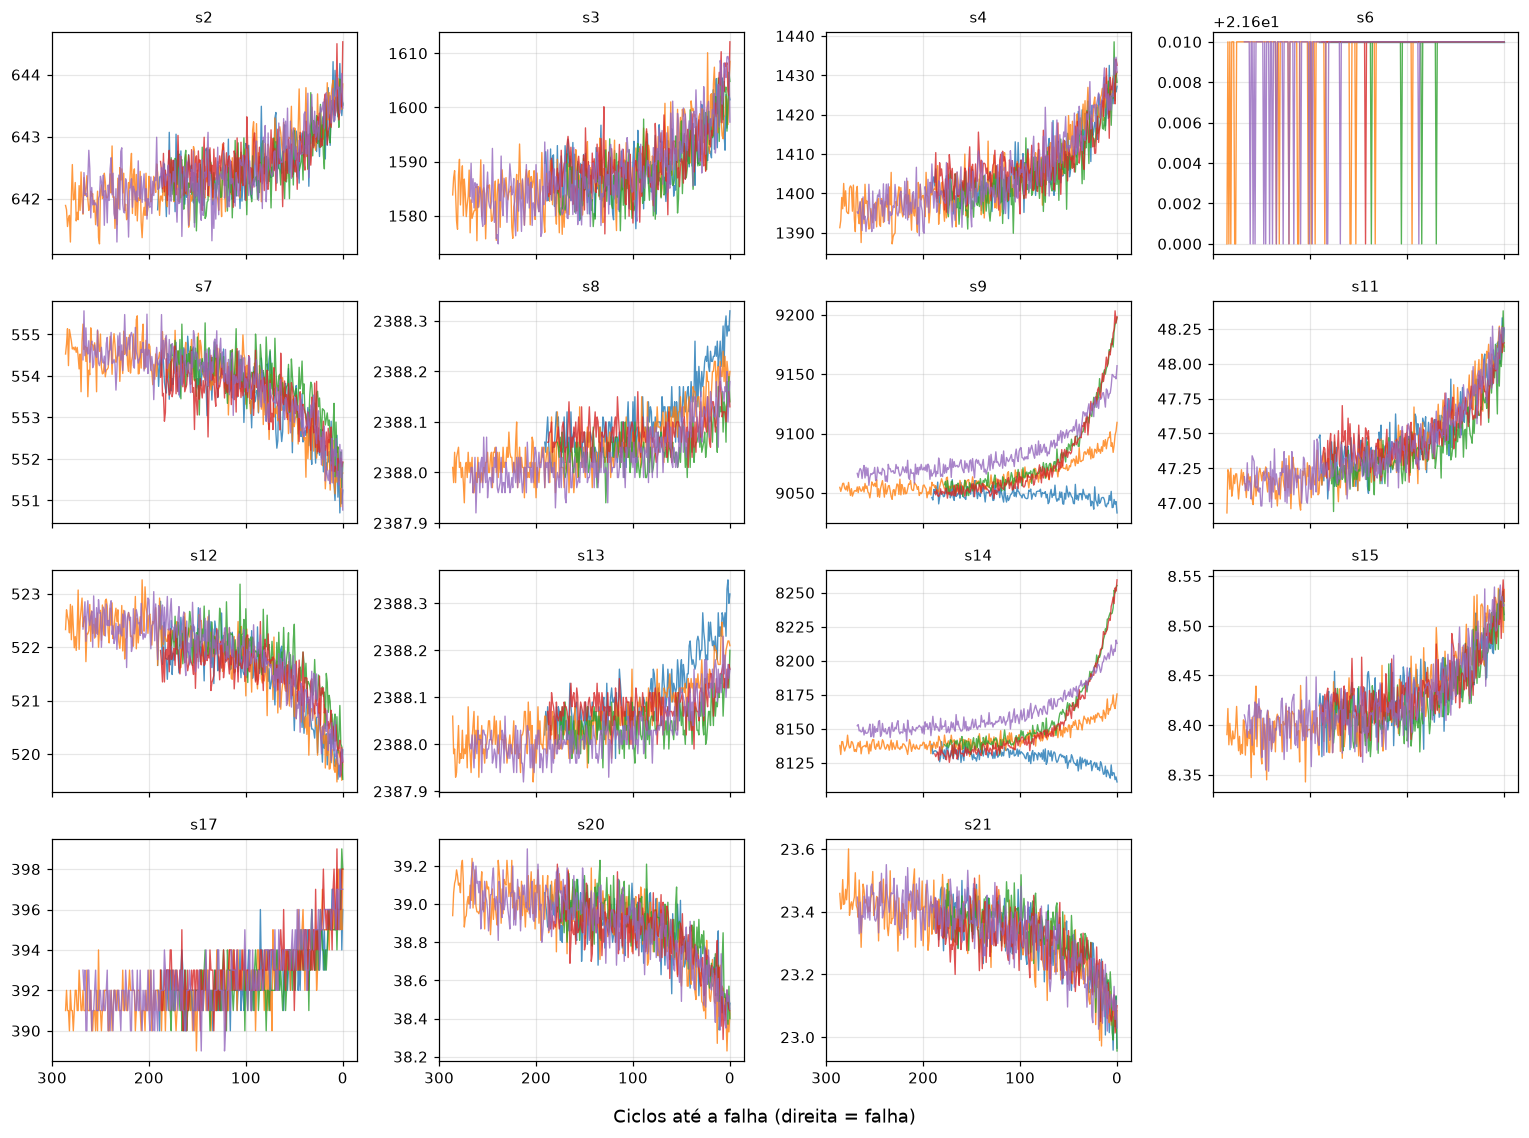

In [6]:
train["ciclos_ate_falha"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

motores = [1, 2, 3, 4, 5]
cols = 4
linhas = int(np.ceil(len(uteis) / cols))
fig, axes = plt.subplots(linhas, cols, figsize=(14, 2.6 * linhas), sharex=True)
for ax, sensor in zip(axes.ravel(), uteis):
    for m in motores:
        d = train[train["unit"] == m]
        ax.plot(d["ciclos_ate_falha"], d[sensor], lw=0.9, alpha=0.8)
    ax.set_title(sensor, fontsize=10)
axes.ravel()[0].invert_xaxis()  # eixos compartilhados: inverter uma única vez
for ax in axes.ravel()[len(uteis):]:
    ax.axis("off")
fig.supxlabel("Ciclos até a falha (direita = falha)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sensores_vs_falha.png")
plt.show()

**Pergunta para você:** quais sensores têm tendência clara perto da falha (sobem ou descem de forma consistente nos 5 motores)?
E quais parecem só ruído? Anote os nomes (ex.: `s2`, `s7`...) antes de seguir para a próxima seção.

R: apartir da observação do grafico podemos ver que alguns sensores tem tendencias diferentes, como:

s2,s3,s4,s8,s11,s13,s15,s17 tendem a subir perto da falha

s7,s12,s20,s21 tendem a descer perto da falha

s6,s6,s14 não tem uma tentencia bem definida podem ter sido afetadas por ruido

## 4. Que sensores se relacionam com a RUL?
Calculamos a **correlação** de cada sensor com a RUL (de -1 a +1; perto de 0 = sem relação linear).
É um guia, não uma regra: relações não lineares podem passar despercebidas.

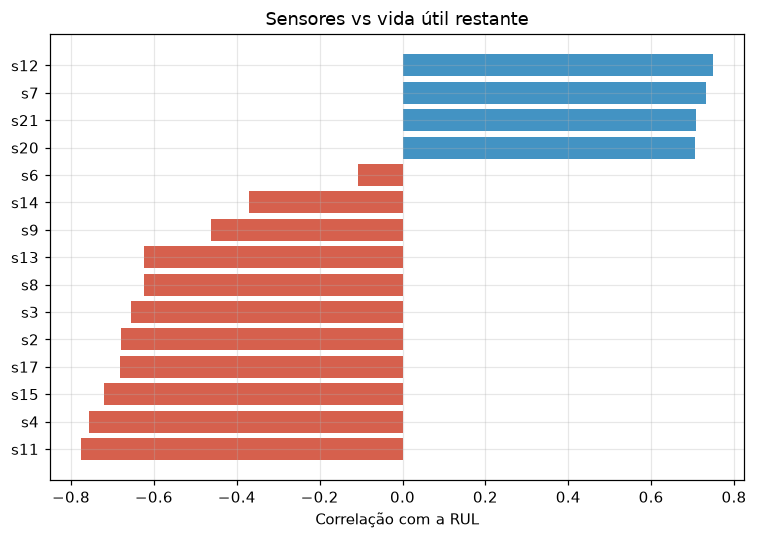

,correlação
s11,-0.775
s4,-0.757
s15,-0.721
s17,-0.681
s2,-0.678
s3,-0.655
s8,-0.625
s13,-0.624
s9,-0.462
s14,-0.370


In [7]:
corr = train[uteis + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
cores = ["#d6604d" if v < 0 else "#4393c3" for v in corr]
ax.barh(corr.index, corr.values, color=cores)
ax.set_xlabel("Correlação com a RUL")
ax.set_title("Sensores vs vida útil restante")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_correlacao_rul.png")
plt.show()

corr.round(3).to_frame("correlação")

In [8]:
fortes = corr[corr.abs() >= 0.5].index.tolist()
print("Sensores com |correlação| >= 0.5:", fortes)

Sensores com |correlação| >= 0.5: ['s11', 's4', 's15', 's17', 's2', 's3', 's8', 's13', 's20', 's21', 's7', 's12']


## 5. Ruído e suavização
Os sensores são ruidosos. Uma **média móvel** costuma revelar a tendência. Veja um sensor antes e depois:

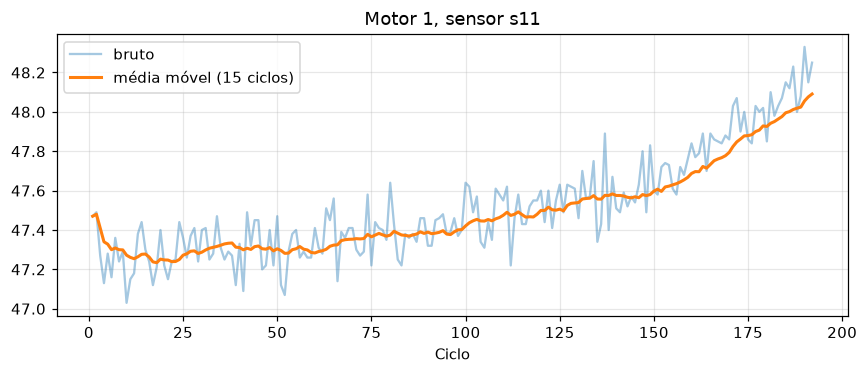

In [9]:
sensor = fortes[0] if fortes else uteis[0]
d = train[train["unit"] == 1].copy()
d["media_movel"] = d[sensor].rolling(window=15, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(d["cycle"], d[sensor], alpha=0.4, label="bruto")
ax.plot(d["cycle"], d["media_movel"], lw=2, label="média móvel (15 ciclos)")
ax.set_xlabel("Ciclo")
ax.set_title(f"Motor 1, sensor {sensor}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_suavizacao.png")
plt.show()

## 6. O que aprendemos (preencha com suas palavras)
- **Motores e ciclos:** temos 100 motores, e temos motores que durou 128 ciclos e até mesmo que duraram 362 ciclos com uma media de 206.3 ciclos por motor
- **Sensores constantes (descartados):** s1, s5,s10,s16,s18,s19, o s6 é quase constante, mas ainda reage entao faz sentido manter ele por enquanto depois avaliar melhor
- **Sensores com tendência clara:**
s2,s3,s4,s8,s11,s13,s15,s17 tendem a subir perto da falha

s7,s12,s20,s21 tendem a descer perto da falha

s6,s9,s14 não é possivel indentificar uma tendencia devido alto ruido, e comportamento q varia entre motores

- **Efeito da média móvel:** suaviza o ruído e revela a tendência de desgaste.

- **Ideia para o próximo passo (modelo):** criar variáveis com médias móveis dos sensores e treinar modelos mais fortes (XGBoost).
